<a href="https://colab.research.google.com/github/AndresMontesDeOca/vision_computadora_II/blob/VpC2_2026/CS_V2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
from IPython.display import Audio, display, HTML

sr = 44100
signal = np.full(sr, 1e-6, dtype=np.float32)

# Renderiza el audio y fuerza loop="loop" en el elemento HTML generado
display(Audio(signal, rate=sr, autoplay=True))
display(HTML("""
<script>
  const audios = document.querySelectorAll('audio');
  audios.forEach(a => { a.loop = true; a.play().catch(() => {}); });
</script>
"""))

# **Clasificación y Detección de Objetos en Counter-Strike**

Este notebook contiene el pipeline completo para descargar un dataset de Counter-Strike desde Roboflow, realizar análisis exploratorio de datos (EDA), entrenar un modelo YOLOv11 de Ultralytics, evaluar las métricas de rendimiento y realizar inferencias/predicciones visuales utilizando Google Drive como almacenamiento persistente.

## **1. Configuración del Entorno e Importación de Librerías**

En esta sección instalamos las dependencias requeridas, montamos Google Drive para persistencia de datos e importamos los módulos necesarios.

In [ ]:
# Instalar librerías necesarias si no están presentes
!pip install roboflow ultralytics

import os
import yaml
import json
import random
import cv2
import glob
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import userdata
from google.colab import drive
from roboflow import Roboflow
from ultralytics import YOLO

# Montar Google Drive al inicio de la sesión
drive.mount('/content/drive')

## **2. Descarga y Verificación del Dataset**

Utilizamos la API de Roboflow para descargar la versión adaptada a YOLOv11 de nuestro dataset de Counter-Strike de manera automatizada.

In [ ]:
# Ruta esperada del dataset
dataset_path = '/content/Counter-Strike-1'

# Verificar si el dataset ya existe en el entorno
if not os.path.exists(dataset_path):
    print("El dataset no fue detectado. Iniciando descarga desde Roboflow...")
    api_key = userdata.get("ROBOFLOW_API_KEY")
    rf = Roboflow(api_key=api_key)

    # Descarga del dataset en formato YOLOv11
    project = rf.workspace("counter-strike-uovxc").project("counter-strike-h9y80")
    version = project.version(1)
    dataset = version.download("yolov11")
else:
    print(f"El dataset ya existe en '{dataset_path}'. Se omitió la descarga para optimizar tiempo.")

## **3. Análisis Exploratorio de Datos (EDA)**

Definimos funciones de visualización para inspeccionar nuestras imágenes de entrenamiento, analizar las distribuciones de clases y resoluciones para asegurar un entrenamiento estable.

In [ ]:
# Cargar y mostrar la configuración de clases y rutas
data_yaml_path = '/content/Counter-Strike-1/data.yaml'
with open(data_yaml_path, 'r') as file:
    dataset_info = yaml.safe_load(file)

print("Estructura y clases del dataset:")
print(json.dumps(dataset_info, indent=4))
print("\n" + "="*40 + "\n")

# --- Conteo de Imágenes por Carpeta ---
dataset_root = '/content/Counter-Strike-1'
for split in ['train', 'val', 'test']:
    yaml_key = split
    if split == 'val' and 'val' not in dataset_info and 'valid' in dataset_info:
        yaml_key = 'valid'

    if yaml_key in dataset_info:
        split_path = dataset_info[yaml_key].lstrip('./').replace('../', '')
        full_split_path = os.path.abspath(os.path.join(dataset_root, split_path))

        image_extensions = ('*.jpg', '*.jpeg', '*.png', '*.bmp', '*.JPG', '*.JPEG', '*.PNG')
        images_found = []
        for ext in image_extensions:
            images_found.extend(glob.glob(os.path.join(full_split_path, ext)))

        print(f"Carpeta '{split}': {len(images_found)} imágenes encontradas en {full_split_path}")
    else:
        print(f"No se encontró la definición de '{split}' o '{yaml_key}' en data.yaml")
print("\n" + "="*40 + "\n")

# Definición de parámetros principales para el EDA
images_dir = '/content/Counter-Strike-1/train/images'
labels_dir = '/content/Counter-Strike-1/train/labels'
class_names = dataset_info.get('names', ['ct', 't'])

# Función para graficar muestras YOLO
def plot_yolo_sample(img_path, lbl_path, class_names):
    if not os.path.exists(img_path):
        return
    image = cv2.imread(img_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    h, w, _ = image.shape
    colors = [(0, 0, 255), (255, 0, 0)]  # Azul para CT, Rojo para Terroristas

    if os.path.exists(lbl_path):
        with open(lbl_path, 'r') as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) == 5:
                    cls_id = int(parts[0])
                    x_center, y_center, bbox_w, bbox_h = map(float, parts[1:])
                    x1 = int((x_center - bbox_w / 2) * w)
                    y1 = int((y_center - bbox_h / 2) * h)
                    x2 = int((x_center + bbox_w / 2) * w)
                    y2 = int((y_center + bbox_h / 2) * h)
                    color = colors[cls_id % len(colors)]
                    cv2.rectangle(image, (x1, y1), (x2, y2), color, 2)
                    label = class_names[cls_id]
                    cv2.putText(image, label, (x1, max(15, y1 - 5)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)

    plt.figure(figsize=(8, 8))
    plt.imshow(image)
    plt.axis('off')
    plt.show()

def plot_random_samples(images_dir, labels_dir, class_names, num_samples=3):
    all_images = [f for f in os.listdir(images_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    selected_images = random.sample(all_images, min(len(all_images), num_samples))
    for img_name in selected_images:
        lbl_name = img_name.rsplit('.', 1)[0] + '.txt'
        plot_yolo_sample(os.path.join(images_dir, img_name), os.path.join(labels_dir, lbl_name), class_names)

# Mostrar muestras aleatorias etiquetadas
plot_random_samples(images_dir, labels_dir, class_names, num_samples=2)

In [ ]:
# Análisis del balance de clases en cada partición
particiones = {
    'Train': '/content/Counter-Strike-1/train/labels',
    'Valid': '/content/Counter-Strike-1/valid/labels',
    'Test': '/content/Counter-Strike-1/test/labels'
}

resultados = {}
for nombre, ruta in particiones.items():
    counts = {0: 0, 1: 0}
    if os.path.exists(ruta):
        for file in os.listdir(ruta):
            if file.endswith('.txt'):
                with open(os.path.join(ruta, file), 'r') as f:
                    for line in f:
                        parts = line.strip().split()
                        if parts:
                            cls_id = int(parts[0])
                            if cls_id in counts:
                                counts[cls_id] += 1
    resultados[nombre] = counts

df_balance = pd.DataFrame(resultados).rename(index={0: 'Counter-Terrorist (ct)', 1: 'Terrorist (t)'})
display(df_balance)

# Graficar Balance de Clases
fig, ax = plt.subplots(figsize=(8, 5))
df_balance.T.plot(kind='bar', ax=ax, color=['royalblue', 'crimson'])
plt.title('Balanceo de Clases por Partición')
plt.ylabel('Cantidad de Instancias')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

## **4. Entrenamiento del Modelo (YOLOv11)**

Inicializamos y entrenamos el detector con arquitectura YOLOv11 utilizando los hiperparámetros óptimos seleccionados.

In [ ]:
# Configuración del flujo de entrenamiento
entrenar = True  # True para entrenar un modelo nuevo, False para saltarlo y cargar pesos previos

# Versión de YOLOv11 a utilizar. Opciones disponibles:
# - "yolo11n.pt" (Nano: extremadamente rápido, ideal para CPU/móviles)
# - "yolo11s.pt" (Small: balance velocidad/precisión)
# - "yolo11m.pt" (Medium: para mayor precisión en detecciones complejas)
# - "yolo11l.pt" (Large: mayor precisión, requiere más memoria GPU)
# - "yolo11x.pt" (X-Large: máxima precisión, entrenamiento más lento)
modelo_version = "yolo11m.pt"

# Hiperparámetros generales de entrenamiento
epocas = 200
paciencia = 15  # Número de épocas a esperar sin mejora antes de detener el entrenamiento (Early Stopping)
seed = 42 # Variable de semilla para garantizar reproducibilidad en todo el pipeline
tamanio_batch = 16


print(f"Configuración cargada:\n- Entrenar: {entrenar}\n- Modelo base: {modelo_version}\n- Épocas: {epocas}\n- Batch size: {tamanio_batch}\n- Paciencia (Early Stopping): {paciencia}\n- Semilla establecida: {seed}")

In [ ]:
import os
import shutil
import random
import numpy as np
import torch

# Configurar reproducibilidad en bibliotecas estándar
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    # Asegurar comportamiento determinista en algoritmos convolucionales de CUDA
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

if entrenar:
    print(f"Iniciando entrenamiento del modelo seleccionado: {modelo_version} con semilla de reproducibilidad {seed}...")
    # Inicializar la arquitectura elegida dinámicamente
    model = YOLO(modelo_version)

    # Comenzar entrenamiento con los parámetros seleccionados por el usuario y fijar la semilla en YOLO
    results = model.train(
        data="/content/Counter-Strike-1/data.yaml",
        epochs=epocas,
        patience=paciencia,
        imgsz=640,
        batch=tamanio_batch,
        project="runs",
        name="cs_v2",
        exist_ok=True,
        seed=seed
    )

    # --- EXPORTACIÓN AUTOMÁTICA E INMEDIATA A GOOGLE DRIVE TRAS ENTRENAR ---
    print("\n--- Iniciando exportación automática de resultados a Google Drive ---")
    modelo_id = modelo_version.replace(".pt", "") if 'modelo_version' in globals() else "yolo11m"

    # Rutas locales origen
    local_results_csv = "runs/detect/runs/cs_v2/results.csv"
    local_best_weights = "runs/detect/runs/cs_v2/weights/best.pt"

    # Rutas destino en Google Drive (Directorio Actualizado)
    drive_dest_dir = '/content/drive/MyDrive/CS_YOLO_Baselines'
    drive_csv_path = os.path.join(drive_dest_dir, f"{modelo_id}_training_metrics_backup.csv")
    drive_weights_path = os.path.join(drive_dest_dir, "weights", f"{modelo_id}_best.pt")

    os.makedirs(os.path.join(drive_dest_dir, "weights"), exist_ok=True)

    # Exportar métricas CSV
    if os.path.exists(local_results_csv):
        try:
            shutil.copy(local_results_csv, drive_csv_path)
            print(f"[OK] Métricas exportadas a Drive: {drive_csv_path}")
        except Exception as e:
            print(f"[ALERTA] Error al exportar CSV de métricas: {e}")

    # Exportar pesos optimizados
    if os.path.exists(local_best_weights):
        try:
            shutil.copy(local_best_weights, drive_weights_path)
            print(f"[OK] Pesos optimizados exportados a Drive: {drive_weights_path}")
        except Exception as e:
            print(f"[ALERTA] Error al exportar pesos: {e}")
else:
    print("\n[INFO] 'entrenar' está desactivado. Se omite el entrenamiento de esta sesión.")
    print("Los pesos y métricas se restaurarán o leerán directamente desde Google Drive en la sección 5.")

In [ ]:
# Cargo los pesos entrenados anterioremente

import os
import shutil
import pandas as pd

# Obtener el nombre base del modelo limpio
modelo_id = modelo_version.replace(".pt", "") if 'modelo_version' in globals() else "yolo11m"

# Directorios locales de destino de la restauración
save_dir = "runs/detect/runs/cs_v2"
local_weights_path = os.path.join(save_dir, "weights", "best.pt")
local_csv_backup_path = os.path.join(save_dir, f"{modelo_id}_training_metrics_backup.csv")
local_target_weights_path = os.path.join(save_dir, "weights", f"{modelo_id}_best.pt")

# Directorios y nombres de archivos en Drive (Única Fuente de Verdad)
drive_dest_dir = '/content/drive/MyDrive/CS_YOLO_Baselines'
drive_csv_path = os.path.join(drive_dest_dir, f"{modelo_id}_training_metrics_backup.csv")
drive_weights_path = os.path.join(drive_dest_dir, "weights", f"{modelo_id}_best.pt")

os.makedirs(save_dir, exist_ok=True)

print(f"[INFO] CARGA EXCLUSIVA: Descargando métricas y pesos directamente desde Google Drive para '{modelo_id}'...")

# 1. Cargar obligatoriamente métricas CSV de Drive
if os.path.exists(drive_csv_path):
    try:
        shutil.copy(drive_csv_path, local_csv_backup_path)
        print(f"[OK] Métricas de '{modelo_id}' cargadas exitosamente desde Drive al entorno local.")
    except Exception as e:
        print(f"[ERROR] No se pudieron copiar las métricas desde Drive: {e}")
else:
    print(f"[ALERTA] No se encontró el archivo de métricas en Drive: {drive_csv_path}")

# 2. Cargar obligatoriamente pesos optimizados de Drive
if os.path.exists(drive_weights_path):
    try:
        os.makedirs(os.path.dirname(local_weights_path), exist_ok=True)
        shutil.copy(drive_weights_path, local_target_weights_path)
        shutil.copy(drive_weights_path, local_weights_path)
        print(f"[OK] Pesos '{modelo_id}_best.pt' descargados exitosamente desde Drive al entorno local.")
    except Exception as e:
        print(f"[ERROR] No se pudieron copiar los pesos desde Drive: {e}")
else:
    print(f"[ALERTA] No se encontraron los pesos en Drive: {drive_weights_path}")

# 3. Mostrar vista previa de métricas cargadas para verificar el dataframe 'df'
if os.path.exists(local_csv_backup_path):
    df = pd.read_csv(local_csv_backup_path)
    display(df.head(5))
else:
    df = None
    print("[INFO] No hay métricas cargadas en memoria.")

## **7. Inferencia y Predicciones en Nuevas Muestras**

Esta sección carga los pesos optimizados del entrenamiento (`best.pt`) y realiza una prueba de predicción visual sobre una imagen aleatoria.

In [ ]:
# Prediccion de 5 imagenes random de test

import os
import random
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

# Configuración de semilla para reproducibilidad (misma selección de imágenes)
# Cambia este valor para ver otro set de 5 imágenes distintas
seed_imagenes = 42

# 1. Selección de 5 imágenes al azar
train_images_dir = "/content/Counter-Strike-1/test/images"
if os.path.exists(train_images_dir):
    # Ordenar la lista para garantizar el mismo orden en cualquier sistema/ejecución
    all_train_images = sorted([f for f in os.listdir(train_images_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))])
    num_imagenes_mostrar = min(len(all_train_images), 5)

    # Aplicar la semilla antes de la selección aleatoria
    random.seed(seed_imagenes)
    selected_images = random.sample(all_train_images, num_imagenes_mostrar)
else:
    raise FileNotFoundError("Directorio de entrenamiento no encontrado.")

# 2. Cargar directamente los pesos del modelo seleccionado desde Google Drive (Directorio Actualizado)
modelo_id = modelo_version.replace(".pt", "") if 'modelo_version' in globals() else "yolo11m"
drive_weights_path = f"/content/drive/MyDrive/CS_YOLO_Baselines/weights/{modelo_id}_best.pt"

print(f"[INFO] Cargando exclusivamente pesos de inferencia desde Google Drive para {modelo_id}...")
if os.path.exists(drive_weights_path):
    print(f"[OK] Pesos cargados exitosamente: {drive_weights_path}")
    inference_model = YOLO(drive_weights_path)
else:
    raise FileNotFoundError(f"[ALERTA] No se encontraron los pesos optimizados en la ruta de Drive: {drive_weights_path}")

# 3. Realizar predicciones y mostrar las 5 imágenes en una cuadrícula
fig, axes = plt.subplots(1, num_imagenes_mostrar, figsize=(20, 5))
if num_imagenes_mostrar == 1:
    axes = [axes]

for idx, img_name in enumerate(selected_images):
    img_path = os.path.join(train_images_dir, img_name)

    # Ejecutar predicción sin guardar logs redundantes
    preds = inference_model.predict(source=img_path, imgsz=640, conf=0.4, save=True, project="runs", name="cs_v2_pred", exist_ok=True, verbose=False)

    # Ruta del archivo guardado por Ultralytics
    result_image_path = os.path.join(preds[0].save_dir, os.path.basename(preds[0].path))

    if os.path.exists(result_image_path):
        img = cv2.imread(result_image_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        axes[idx].imshow(img)
        axes[idx].set_title(f"Muestra {idx+1}")
        axes[idx].axis("off")
    else:
        axes[idx].text(0.5, 0.5, "Error al cargar imagen", ha='center', va='center')
        axes[idx].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Performance en test

import os
import json
import shutil
from ultralytics import YOLO

# 1. Definir rutas de los pesos específicos en Google Drive (Directorio Actualizado)
modelo_id = modelo_version.replace(".pt", "") if 'modelo_version' in globals() else "yolo11m"
drive_dest_dir = '/content/drive/MyDrive/CS_YOLO_Baselines'
drive_weights_path = f"{drive_dest_dir}/weights/{modelo_id}_best.pt"

# Forzar la carga exclusiva desde Google Drive
if os.path.exists(drive_weights_path):
    print(f"[INFO] Cargando exclusivamente pesos desde Google Drive para evaluación: {drive_weights_path}")
    model_eval = YOLO(drive_weights_path)
else:
    raise FileNotFoundError(f"[ALERTA] No se encontraron los pesos en Google Drive: {drive_weights_path}")

# 2. Ejecutar la validación en el conjunto de prueba (split='test')
print(f"\n--- Iniciando Evaluación en el Conjunto de Test para {modelo_id} ---")
metrics_test = model_eval.val(
    data="/content/Counter-Strike-1/data.yaml",
    split="test",
    imgsz=640,
    project="runs",
    name="cs_v2_test_evaluation",
    exist_ok=True
)

# 3. Extraer métricas con el formato exacto requerido por el usuario
test_results = {
    "modelo_id": modelo_id,
    "mAP@50": round(metrics_test.box.map50, 4),
    "mAP@50-95": round(metrics_test.box.map, 4),
    "Precision": round(metrics_test.box.mp, 4),
    "Recall": round(metrics_test.box.mr, 4),
    "Latencia Inferencia (ms)": round(metrics_test.speed['inference'], 2),
    "FPS": round(1000.0 / metrics_test.speed['inference'], 1)
}

# 4. Guardar y respaldar las métricas JSON directamente en Google Drive
json_file_name = f"{modelo_id}_test_metrics_backup.json"
local_json_path = os.path.join("runs/detect/runs/cs_v2", json_file_name)
drive_json_path = os.path.join(drive_dest_dir, json_file_name)

# Guardar copia local y copiar directamente a Drive de manera obligatoria
os.makedirs(os.path.dirname(local_json_path), exist_ok=True)
with open(local_json_path, 'w') as f:
    json.dump(test_results, f, indent=4)

try:
    os.makedirs(drive_dest_dir, exist_ok=True)
    shutil.copy(local_json_path, drive_json_path)
    print(f"\n[OK] Métricas de test de '{modelo_id}' exportadas directamente a Drive con éxito: {drive_json_path}")
except Exception as e:
    print(f"\n[ALERTA] Error al escribir el archivo de métricas de test en Google Drive: {e}")

# 5. Mostrar resultados por pantalla
print("\n" + "="*50)
print("     MÉTRICAS FINALES EN EL CONJUNTO DE TEST")
print("="*50)
print(f"mAP@50:                  {test_results['mAP@50']:.4f}")
print(f"mAP@50-95:               {test_results['mAP@50-95']:.4f}")
print(f"Precisión (Precision):   {test_results['Precision']:.4f}")
print(f"Exhaustividad (Recall):  {test_results['Recall']:.4f}")
print(f"Latencia Inferencia:     {test_results['Latencia Inferencia (ms)']} ms")
print(f"FPS:                     {test_results['FPS']}")
print("="*50)

## **9. YOLOv11 Medium: Data Augmentation & Optimization**

Esta sección está reservada para que realices experimentos con técnicas de *Data Augmentation* personalizadas (ajustes de brillo, contraste, mosaicos o desenfoques) y optimización de hiperparámetros aplicados al modelo **YOLOv11 Medium**, con el fin de superar el rendimiento actual en la detección de Terroristas (t) y Anti-Terroristas (ct) en Counter-Strike.

In [ ]:
# Comparacion durante el entrenamiento (Sin busqueda profunda recursiva)

import os
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

# Forzar remonte seguro de Google Drive para actualizar el caché de archivos
try:
    drive.mount('/content/drive', force_remount=True)
except Exception as e:
    print(f"[INFO] Nota sobre el montaje de Drive: {e}")

# Directorio Único y Consolidado (Única ruta válida en Drive)
drive_metrics_dir = '/content/drive/MyDrive/CS_YOLO_Baselines'

# Lista de modelos ordenados de menor a mayor peso
modelos_ordenados = [
    {"id": "yolo11n", "nombre": "YOLOv11 Nano (yolo11n)"},
    {"id": "yolo11s", "nombre": "YOLOv11 Small (yolo11s)"},
    {"id": "yolo11m", "nombre": "YOLOv11 Medium (yolo11m)"},
    {"id": "yolo11l", "nombre": "YOLOv11 Large (yolo11l)"},
    {"id": "yolo11x", "nombre": "YOLOv11 X-Large (yolo11x)"}
]

# Colores muy contrastados para distinguir fácilmente cada modelo con líneas continuas
colores_contraste = [
    '#E6194B',  # Rojo
    '#3CB44B',  # Verde
    '#0082C8',  # Azul
    '#F58231',  # Naranja
    '#911EB4'   # Púrpura
]

plt.figure(figsize=(12, 7))
modelos_graficados = 0

print("Buscando archivos de métricas únicamente en el directorio consolidado...")
for i, mod in enumerate(modelos_ordenados):
    csv_name = f"{mod['id']}_training_metrics_backup.csv"

    # Rutas estrictas (Drive oficial o local de esta sesión)
    path_drive = os.path.join(drive_metrics_dir, csv_name)
    path_local = os.path.join("runs/detect/runs/cs_v2", csv_name)
    path_results_local = "runs/detect/runs/cs_v2/results.csv"

    target_path = None
    if os.path.exists(path_drive):
        target_path = path_drive
    elif os.path.exists(path_local):
        target_path = path_local
    elif mod['id'] == 'yolo11l' and os.path.exists(path_results_local):
        target_path = path_results_local

    if target_path:
        print(f" -> Cargando {mod['id']} desde: {target_path}")
        df_mod = pd.read_csv(target_path)
        df_mod.columns = df_mod.columns.str.strip()

        # Graficar con línea continua utilizando el color de alto contraste correspondiente
        plt.plot(
            df_mod["epoch"],
            df_mod["metrics/mAP50-95(B)"],
            label=mod["nombre"],
            color=colores_contraste[i],
            linewidth=1.8
        )
        modelos_graficados += 1
    else:
        print(f" -> [Omitido] No se encontró el archivo para {mod['id']} en la carpeta {drive_metrics_dir}")

if modelos_graficados > 0:
    plt.title("Comparativa de Entrenamiento: mAP50-95(B) vs Épocas", fontsize=14, fontweight='bold', pad=15)
    plt.xlabel("Épocas (Epoch)", fontsize=11)
    plt.ylabel("mAP50-95 (Box)", fontsize=11)
    plt.ylim(0.0, 0.6)
    plt.xlim(left=1)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend(loc="lower left", fontsize=10, frameon=True, shadow=True)
    plt.tight_layout()
    plt.show()
else:
    print("[ALERTA] No se pudo localizar ningún archivo .csv en la ruta consolidada del Drive. Verifique los respaldos de entrenamiento.")

In [ ]:
# Comparacion performance en test (Sin busqueda profunda recursiva)

import os
import json
import pandas as pd
import matplotlib.pyplot as plt

# Directorio Único y Consolidado (Única ruta válida en Drive)
drive_metrics_dir = '/content/drive/MyDrive/CS_YOLO_Baselines'

# Lista de modelos ordenados
modelos_ordenados = [
    {"id": "yolo11n", "nombre": "YOLOv11 Nano (yolo11n)"},
    {"id": "yolo11s", "nombre": "YOLOv11 Small (yolo11s)"},
    {"id": "yolo11m", "nombre": "YOLOv11 Medium (yolo11m)"},
    {"id": "yolo11l", "nombre": "YOLOv11 Large (yolo11l)"},
    {"id": "yolo11x", "nombre": "YOLOv11 X-Large (yolo11x)"}
]

# Colores muy contrastados consistentes con las gráficas anteriores
colores_contraste = [
    '#E6194B',  # Rojo
    '#3CB44B',  # Verde
    '#0082C8',  # Azul
    '#F58231',  # Naranja
    '#911EB4'   # Púrpura
]

datos_test = []

print("Buscando archivos de métricas de test (.json) únicamente en el directorio consolidado...")
for mod in modelos_ordenados:
    json_name = f"{mod['id']}_test_metrics_backup.json"
    path_drive = os.path.join(drive_metrics_dir, json_name)

    if os.path.exists(path_drive):
        print(f" -> Cargando JSON de test para {mod['id']} desde: {path_drive}")
        with open(path_drive, 'r') as f:
            metricas = json.load(f)
            # Soportar ambas nomenclaturas anteriores ('mAP50-95' o 'mAP@50-95') de forma flexible
            map_val = metricas.get("mAP@50-95", metricas.get("mAP50-95", 0.0))
            datos_test.append({
                "Modelo": mod["nombre"],
                "mAP50-95": map_val
            })
    else:
        print(f" -> [Omitido] No se encontró el JSON de test para {mod['id']} en la carpeta {drive_metrics_dir}")

if datos_test:
    # Crear DataFrame de comparación
    df_test_comp = pd.DataFrame(datos_test).set_index("Modelo")

    # Mostrar tabla descriptiva enfocada
    print("\n--- TABLA COMPARATIVA EN TEST (mAP50-95) ---")
    display(df_test_comp.round(4))

    # Crear gráfico de barras individuales exclusivas de mAP50-95
    plt.figure(figsize=(10, 6))
    bars = plt.bar(
        df_test_comp.index,
        df_test_comp["mAP50-95"],
        color=colores_contraste[:len(datos_test)],
        edgecolor='black',
        width=0.6
    )

    plt.title("Comparativa de Mean Average Precision en Test", fontsize=14, fontweight='bold', pad=20)
    plt.ylabel("mAP50-95", fontsize=11)
    plt.ylim(0.0, 0.6)
    plt.xticks(rotation=15, ha='right', fontsize=10)
    plt.grid(axis='y', linestyle='--', alpha=0.5)

    # Agregar valores encima de cada barra para lectura exacta
    for bar in bars:
        yval = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width()/2.0,
            yval + 0.01,
            f"{yval:.4f}",
            ha='center',
            va='bottom',
            fontsize=11,
            fontweight='bold'
        )

    plt.tight_layout()
    plt.show()
else:
    print("\n[ALERTA] No se encontraron archivos JSON de métricas de test en la carpeta consolidada del Drive.")

## **10. Experimento Especial: Entrenamiento Desde Cero (From Scratch)**

En esta sección entrenamos el modelo **YOLOv11** inicializándolo de forma completamente aleatoria, sin utilizar pesos preentrenados de ImageNet (*Transfer Learning*).

Para evitar interferir con las ejecuciones anteriores, todos los artefactos de este experimento (pesos y métricas en Google Drive) se identificarán con el prefijo especial **`yolo11X_`**.

In [35]:
# Celda de Limpieza y Reseteo de Memoria GPU / RAM antes de entrenar
import torch
import gc

def limpiar_memoria_entorno():
    print("--- Iniciando proceso de limpieza de memoria ---")

    # 1. Eliminar variables pesadas del modelo anterior si existen en el espacio de nombres
    variables_a_borrar = ['model', 'model_eval', 'inference_model', 'results', 'results_scratch', 'model_scratch']
    borradas = []
    for var in variables_a_borrar:
        if var in globals():
            del globals()[var]
            borradas.append(var)
    if borradas:
        print(f"[OK] Variables eliminadas de la memoria global: {', '.join(borradas)}")

    # 2. Forzar el recolector de basura de Python
    gc.collect()
    print("[OK] Recolector de basura de Python (GC) ejecutado.")

    # 3. Vaciar caché de PyTorch CUDA
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()
        dispositivo = torch.cuda.get_device_name(0)
        memoria_reservada = torch.cuda.memory_reserved(0) / 1024**2
        memoria_asignada = torch.cuda.memory_allocated(0) / 1024**2
        print(f"[OK] Caché de CUDA vaciada exitosamente en: {dispositivo}")
        print(f"     Memoria VRAM Reservada: {memoria_reservada:.2f} MB")
        print(f"     Memoria VRAM Asignada Actual: {memoria_asignada:.2f} MB")
    else:
        print("[INFO] No hay dispositivo CUDA activo para limpiar.")

# Ejecutar la limpieza
limpiar_memoria_entorno()

--- Iniciando proceso de limpieza de memoria ---
[OK] Variables eliminadas de la memoria global: model, model_eval, inference_model, results, results_scratch, model_scratch
[OK] Recolector de basura de Python (GC) ejecutado.
[OK] Caché de CUDA vaciada exitosamente en: Tesla T4
     Memoria VRAM Reservada: 1166.00 MB
     Memoria VRAM Asignada Actual: 787.61 MB


In [36]:
# Configuración del experimento From Scratch (Sin pesos preentrenados)
entrenar_scratch = True
modelo_scratch_version = "yolo11s"  # Comenzamos por la versión Nano (yolo11n) tal como solicitaste
epocas_scratch = 200
tamanio_batch_scratch = 16
paciencia_scratch = 15
seed_scratch = 42

import os
import shutil
import random
import numpy as np
import torch
from ultralytics import YOLO

# Asegurar reproducibilidad de la semilla
random.seed(seed_scratch)
np.random.seed(seed_scratch)
torch.manual_seed(seed_scratch)
if torch.cuda.is_available():
    torch.cuda.manual_seed(seed_scratch)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

if entrenar_scratch:
    print(f"[INFO] Inicializando {modelo_scratch_version} desde cero (FROM SCRATCH)... ")

    # Cargamos el archivo de configuración (.yaml) para inicializar los pesos aleatoriamente
    # en lugar del archivo (.pt) que contiene los pesos preentrenados.
    model_scratch = YOLO(f"{modelo_scratch_version}.yaml")

    print("Comenzando entrenamiento...")
    results_scratch = model_scratch.train(
        data="/content/Counter-Strike-1/data.yaml",
        epochs=epocas_scratch,
        patience=paciencia_scratch,
        imgsz=640,
        batch=tamanio_batch_scratch,
        project="runs",
        name="cs_scratch",
        exist_ok=True,
        seed=seed_scratch,
        pretrained=False  # Refuerzo explícito para no utilizar pesos preentrenados
    )

    # --- EXPORTACIÓN AUTOMÁTICA A GOOGLE DRIVE TRAS ENTRENAR CON SUFIJO _B ---
    print("\n--- Exportando resultados 'From Scratch' a Google Drive ---")

    local_results_csv = "runs/detect/runs/cs_scratch/results.csv"
    local_best_weights = "runs/detect/runs/cs_scratch/weights/best.pt"

    drive_dest_dir = '/content/drive/MyDrive/CS_YOLO_Baselines'
    drive_csv_path = os.path.join(drive_dest_dir, f"{modelo_scratch_version}_B_training_metrics_backup.csv")
    drive_weights_path = os.path.join(drive_dest_dir, "weights", f"{modelo_scratch_version}_B_best.pt")

    os.makedirs(os.path.join(drive_dest_dir, "weights"), exist_ok=True)

    # Copiar métricas CSV
    if os.path.exists(local_results_csv):
        try:
            shutil.copy(local_results_csv, drive_csv_path)
            print(f"[OK] Métricas guardadas con éxito en: {drive_csv_path}")
        except Exception as e:
            print(f"[ALERTA] Error al exportar CSV de métricas: {e}")

    # Copiar pesos optimizados
    if os.path.exists(local_best_weights):
        try:
            shutil.copy(local_best_weights, drive_weights_path)
            print(f"[OK] Pesos optimizados guardados con éxito en: {drive_weights_path}")
        except Exception as e:
            print(f"[ALERTA] Error al exportar pesos: {e}")
else:
    print("[INFO] 'entrenar_scratch' está desactivado. Se omite el entrenamiento de esta sesión.")

[INFO] Inicializando yolo11s desde cero (FROM SCRATCH)... 
Comenzando entrenamiento...
Ultralytics 8.4.220 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Counter-Strike-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=200, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.yaml, momentum=0.937

### **10.1. Evaluación en el Conjunto de Test (From Scratch)**

Evaluamos el rendimiento final del modelo entrenado sin preentrenamiento sobre el conjunto de prueba independiente y respaldamos las métricas en un archivo JSON con la nomenclatura `_B_test_metrics_backup.json` en Google Drive.

In [37]:
# Evaluación de Test para el experimento From Scratch
evaluar_scratch_test = True
modelo_scratch_version = "yolo11n"

import os
import json
import shutil
from ultralytics import YOLO

if evaluar_scratch_test:
    drive_dest_dir = '/content/drive/MyDrive/CS_YOLO_Baselines'
    # Ruta a los pesos entrenados desde cero
    scratch_weights_path = os.path.join(drive_dest_dir, "weights", f"{modelo_scratch_version}_B_best.pt")

    if os.path.exists(scratch_weights_path):
        print(f"[INFO] Cargando pesos 'From Scratch' desde Drive para evaluación en Test: {scratch_weights_path}")
        model_scratch_eval = YOLO(scratch_weights_path)

        print(f"\n--- Iniciando Evaluación en Test (Scratch) para {modelo_scratch_version}_B ---")
        metrics_scratch_test = model_scratch_eval.val(
            data="/content/Counter-Strike-1/data.yaml",
            split="test",
            imgsz=640,
            project="runs",
            name="cs_scratch_test_evaluation",
            exist_ok=True
        )

        # Estructurar métricas finales
        scratch_test_results = {
            "modelo_id": f"{modelo_scratch_version}_B",
            "mAP@50": round(metrics_scratch_test.box.map50, 4),
            "mAP@50-95": round(metrics_scratch_test.box.map, 4),
            "Precision": round(metrics_scratch_test.box.mp, 4),
            "Recall": round(metrics_scratch_test.box.mr, 4),
            "Latencia Inferencia (ms)": round(metrics_scratch_test.speed['inference'], 2),
            "FPS": round(1000.0 / metrics_scratch_test.speed['inference'], 1)
        }

        # Definir rutas para el JSON de respaldo
        json_file_name = f"{modelo_scratch_version}_B_test_metrics_backup.json"
        local_json_path = os.path.join("runs/detect/runs/cs_scratch", json_file_name)
        drive_json_path = os.path.join(drive_dest_dir, json_file_name)

        # Guardar local y exportar a Drive
        os.makedirs(os.path.dirname(local_json_path), exist_ok=True)
        with open(local_json_path, 'w') as f:
            json.dump(scratch_test_results, f, indent=4)

        try:
            shutil.copy(local_json_path, drive_json_path)
            print(f"\n[OK] Métricas de test de '{modelo_scratch_version}_B' exportadas a Drive con éxito: {drive_json_path}")
        except Exception as e:
            print(f"\n[ALERTA] Error al copiar el archivo JSON a Google Drive: {e}")

        # Mostrar resumen por pantalla
        print("\n" + "="*50)
        print("   MÉTRICAS FINALES 'FROM SCRATCH' EN TEST")
        print("="*50)
        print(f"mAP@50:                  {scratch_test_results['mAP@50']:.4f}")
        print(f"mAP@50-95:               {scratch_test_results['mAP@50-95']:.4f}")
        print(f"Precisión (Precision):   {scratch_test_results['Precision']:.4f}")
        print(f"Exhaustividad (Recall):  {scratch_test_results['Recall']:.4f}")
        print(f"Latencia Inferencia:     {scratch_test_results['Latencia Inferencia (ms)']} ms")
        print(f"FPS:                     {scratch_test_results['FPS']}")
        print("="*50)
    else:
        print(f"[ALERTA] No se encontraron los pesos en {scratch_weights_path}. Asegúrate de haber completado el entrenamiento primero.")
else:
    print("[INFO] 'evaluar_scratch_test' está desactivado.")

[INFO] Cargando pesos 'From Scratch' desde Drive para evaluación en Test: /content/drive/MyDrive/CS_YOLO_Baselines/weights/yolo11n_B_best.pt

--- Iniciando Evaluación en Test (Scratch) para yolo11n_B ---
Ultralytics 8.4.220 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,582,542 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2453.4±644.7 MB/s, size: 58.7 KB)
val: Scanning /content/Counter-Strike-1/test/labels.cache... 368 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 368/368 154.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 23/23 5.9it/s 3.9s
                   all        368        479      0.926      0.864      0.918      0.493
                    ct        219        246      0.909      0.856      0.921      0.504
                     t        202        233      0.943      0.871      0.914      0.482
Speed: 0.8

[INFO] Generando comparativas dinámicas para el modelo base: yolo11n


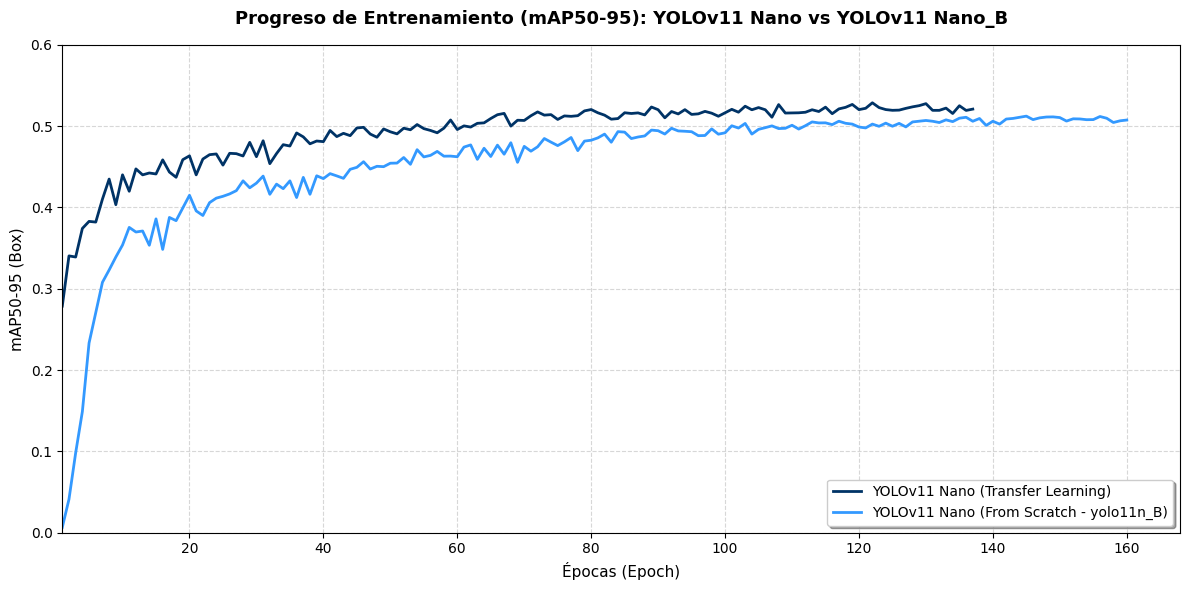

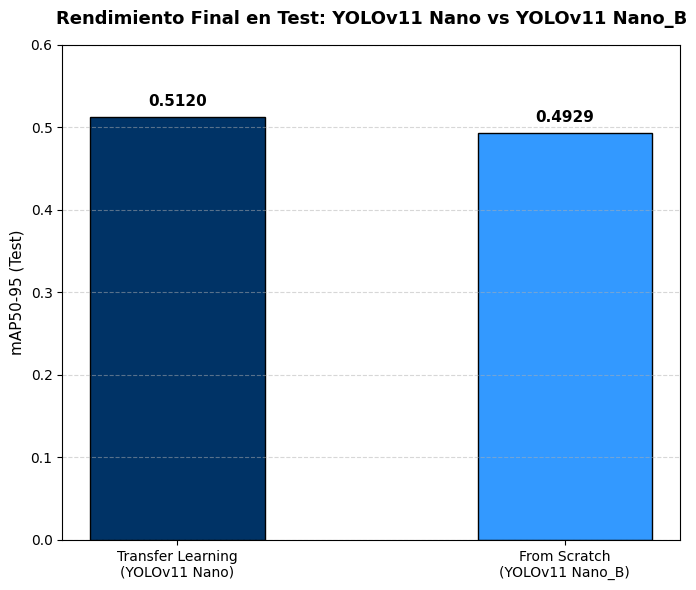

In [39]:
import os
import json
import pandas as pd
import matplotlib.pyplot as plt

# 1. Detectar dinámicamente la versión activa desde el entorno global
modelo_id_activo = globals().get('modelo_scratch_version', 'yolo11n')
print(f"[INFO] Generando comparativas dinámicas para el modelo base: {modelo_id_activo}")

# Diccionario dinámico para formatear los nombres legibles de los modelos
mapeo_nombres = {
    "yolo11n": "YOLOv11 Nano",
    "yolo11s": "YOLOv11 Small",
    "yolo11m": "YOLOv11 Medium",
    "yolo11l": "YOLOv11 Large",
    "yolo11x": "YOLOv11 X-Large"
}

nombre_base_legible = mapeo_nombres.get(modelo_id_activo.lower(), f"YOLOv11 {modelo_id_activo.upper()}")

# Directorio consolidado de métricas en Drive
drive_metrics_dir = '/content/drive/MyDrive/CS_YOLO_Baselines'

# 2. Construcción paramétrica de rutas de archivos (Entrenamiento)
csv_transfer = os.path.join(drive_metrics_dir, f"{modelo_id_activo}_training_metrics_backup.csv")
csv_scratch = os.path.join(drive_metrics_dir, f"{modelo_id_activo}_B_training_metrics_backup.csv")

# 3. Construcción paramétrica de rutas de archivos (Test)
json_transfer = os.path.join(drive_metrics_dir, f"{modelo_id_activo}_test_metrics_backup.json")
json_scratch = os.path.join(drive_metrics_dir, f"{modelo_id_activo}_B_test_metrics_backup.json")

# Paleta de colores solicitada
color_transfer = '#003366'  # Azul oscuro
color_scratch = '#3399FF'   # Celeste

# =========================================================================
# PLOT 1: Comparativa durante el entrenamiento (mAP50-95 vs Épocas)
# =========================================================================
plt.figure(figsize=(12, 6))
grafico_curva_valido = False

# Cargar curvas de Transfer Learning
if os.path.exists(csv_transfer):
    df_trans = pd.read_csv(csv_transfer)
    df_trans.columns = df_trans.columns.str.strip()
    plt.plot(
        df_trans['epoch'],
        df_trans['metrics/mAP50-95(B)'],
        label=f'{nombre_base_legible} (Transfer Learning)',
        color=color_transfer,
        linewidth=2
    )
    grafico_curva_valido = True
else:
    print(f"[ALERTA] No se encontró el archivo CSV de entrenamiento para: {modelo_id_activo}")

# Cargar curvas de From Scratch (Versión _B)
if os.path.exists(csv_scratch):
    df_scrat = pd.read_csv(csv_scratch)
    df_scrat.columns = df_scrat.columns.str.strip()
    plt.plot(
        df_scrat['epoch'],
        df_scrat['metrics/mAP50-95(B)'],
        label=f'{nombre_base_legible} (From Scratch - {modelo_id_activo}_B)',
        color=color_scratch,
        linewidth=2
    )
    grafico_curva_valido = True
else:
    print(f"[ALERTA] No se encontró el archivo CSV de entrenamiento para: {modelo_id_activo}_B")

if grafico_curva_valido:
    plt.title(f'Progreso de Entrenamiento (mAP50-95): {nombre_base_legible} vs {nombre_base_legible}_B', fontsize=13, fontweight='bold', pad=15)
    plt.xlabel('Épocas (Epoch)', fontsize=11)
    plt.ylabel('mAP50-95 (Box)', fontsize=11)
    plt.ylim(0.0, 0.6)
    plt.xlim(left=1)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend(loc='lower right', fontsize=10, frameon=True, shadow=True)
    plt.tight_layout()
    plt.show()
else:
    print("[ALERTA] Sin datos suficientes en CSV para graficar las curvas de aprendizaje.")

# =========================================================================
# PLOT 2: Comparativa de rendimiento final en Test (Barras)
# =========================================================================
modelos_test = []
valores_test = []

# Cargar métrica de Test - Transfer Learning
if os.path.exists(json_transfer):
    with open(json_transfer, 'r') as f:
        data_t = json.load(f)
        modelos_test.append(f'Transfer Learning\n({nombre_base_legible})')
        valores_test.append(data_t.get('mAP@50-95', data_t.get('mAP50-95', 0.0)))
else:
    print(f"[ALERTA] No se encontró el JSON de test para: {modelo_id_activo}")

# Cargar métrica de Test - From Scratch
if os.path.exists(json_scratch):
    with open(json_scratch, 'r') as f:
        data_s = json.load(f)
        modelos_test.append(f'From Scratch\n({nombre_base_legible}_B)')
        valores_test.append(data_s.get('mAP@50-95', data_s.get('mAP50-95', 0.0)))
else:
    print(f"[ALERTA] No se encontró el JSON de test para: {modelo_id_activo}_B")

if len(valores_test) > 0:
    plt.figure(figsize=(7, 6))
    colores_barras = [color_transfer, color_scratch][:len(valores_test)]

    bars = plt.bar(
        modelos_test,
        valores_test,
        color=colores_barras,
        edgecolor='black',
        width=0.45
    )

    plt.title(f'Rendimiento Final en Test: {nombre_base_legible} vs {nombre_base_legible}_B', fontsize=13, fontweight='bold', pad=15)
    plt.ylabel('mAP50-95 (Test)', fontsize=11)
    plt.ylim(0.0, 0.6)
    plt.grid(axis='y', linestyle='--', alpha=0.5)

    # Anotar valores arriba de las barras
    for bar in bars:
        yval = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width()/2.0,
            yval + 0.01,
            f"{yval:.4f}",
            ha='center',
            va='bottom',
            fontsize=11,
            fontweight='bold'
        )

    plt.tight_layout()
    plt.show()
else:
    print("[ALERTA] No hay datos de test disponibles (archivos JSON) para realizar el gráfico de barras comparativo.")

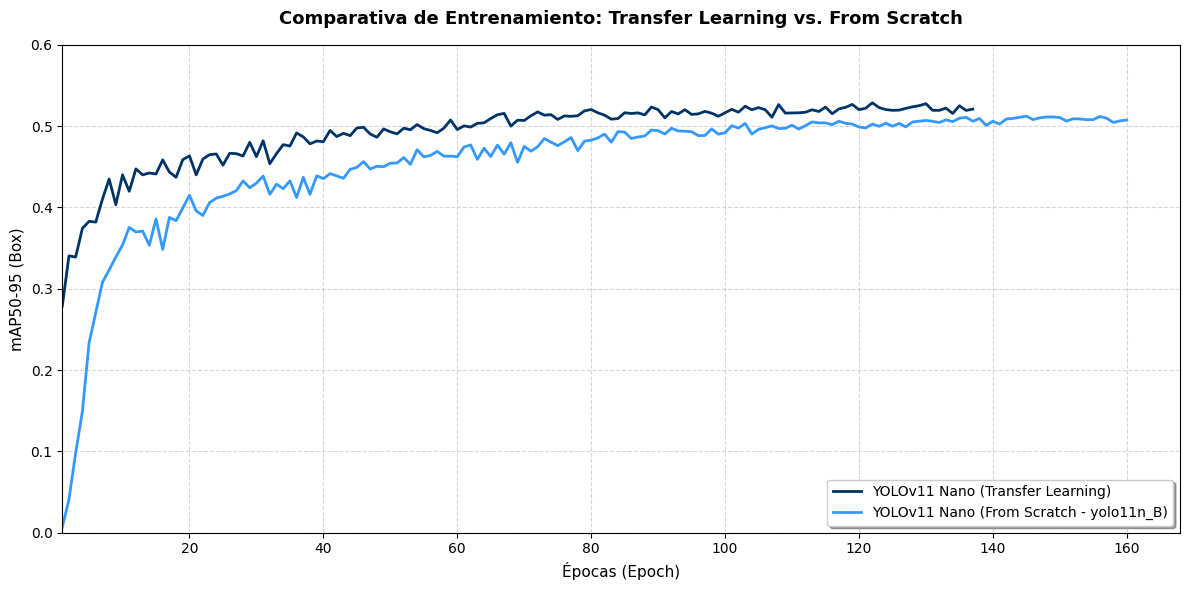

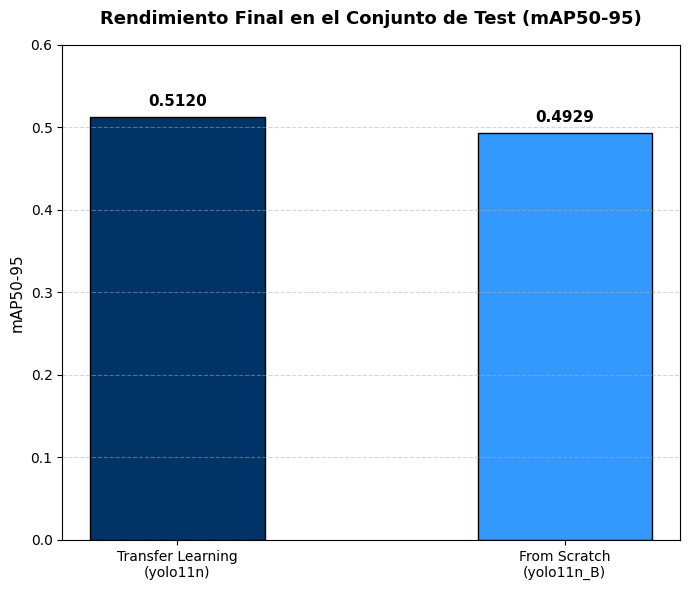

In [38]:
import os
import json
import pandas as pd
import matplotlib.pyplot as plt

# Directorio consolidado de métricas en Drive
drive_metrics_dir = '/content/drive/MyDrive/CS_YOLO_Baselines'

# 1. Rutas de archivos de entrenamiento (CSV)
csv_transfer = os.path.join(drive_metrics_dir, 'yolo11n_training_metrics_backup.csv')
csv_scratch = os.path.join(drive_metrics_dir, 'yolo11n_B_training_metrics_backup.csv')

# 2. Rutas de archivos de test (JSON)
json_transfer = os.path.join(drive_metrics_dir, 'yolo11n_test_metrics_backup.json')
json_scratch = os.path.join(drive_metrics_dir, 'yolo11n_B_test_metrics_backup.json')

# Colores solicitados
color_transfer = '#003366'  # Azul oscuro
color_scratch = '#3399FF'   # Celeste

# =========================================================================
# PLOT 1: Comparativa durante el entrenamiento (mAP50-95 vs Épocas)
# =========================================================================
plt.figure(figsize=(12, 6))
grafico_valido = False

if os.path.exists(csv_transfer):
    df_trans = pd.read_csv(csv_transfer)
    df_trans.columns = df_trans.columns.str.strip()
    plt.plot(
        df_trans['epoch'],
        df_trans['metrics/mAP50-95(B)'],
        label='YOLOv11 Nano (Transfer Learning)',
        color=color_transfer,
        linewidth=2
    )
    grafico_valido = True
else:
    print("[ALERTA] No se encontró el CSV de entrenamiento para Transfer Learning (yolo11n)")

if os.path.exists(csv_scratch):
    df_scrat = pd.read_csv(csv_scratch)
    df_scrat.columns = df_scrat.columns.str.strip()
    plt.plot(
        df_scrat['epoch'],
        df_scrat['metrics/mAP50-95(B)'],
        label='YOLOv11 Nano (From Scratch - yolo11n_B)',
        color=color_scratch,
        linewidth=2
    )
    grafico_valido = True
else:
    print("[ALERTA] No se encontró el CSV de entrenamiento para From Scratch (yolo11n_B)")

if grafico_valido:
    plt.title('Comparativa de Entrenamiento: Transfer Learning vs. From Scratch', fontsize=13, fontweight='bold', pad=15)
    plt.xlabel('Épocas (Epoch)', fontsize=11)
    plt.ylabel('mAP50-95 (Box)', fontsize=11)
    plt.ylim(0.0, 0.6)
    plt.xlim(left=1)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend(loc='lower right', fontsize=10, frameon=True, shadow=True)
    plt.tight_layout()
    plt.show()
else:
    print("[ALERTA] No se pudieron generar las curvas de entrenamiento debido a falta de archivos.")

# =========================================================================
# PLOT 2: Comparativa de rendimiento final en Test (Barras)
# =========================================================================
modelos_test = []
valores_test = []

if os.path.exists(json_transfer):
    with open(json_transfer, 'r') as f:
        m_trans = json.load(f)
        modelos_test.append('Transfer Learning\n(yolo11n)')
        valores_test.append(m_trans.get('mAP@50-95', m_trans.get('mAP50-95', 0.0)))

if os.path.exists(json_scratch):
    with open(json_scratch, 'r') as f:
        m_scrat = json.load(f)
        modelos_test.append('From Scratch\n(yolo11n_B)')
        valores_test.append(m_scrat.get('mAP@50-95', m_scrat.get('mAP50-95', 0.0)))

if len(valores_test) > 0:
    plt.figure(figsize=(7, 6))
    colores_barras = [color_transfer, color_scratch][:len(valores_test)]

    bars = plt.bar(
        modelos_test,
        valores_test,
        color=colores_barras,
        edgecolor='black',
        width=0.45
    )

    plt.title('Rendimiento Final en el Conjunto de Test (mAP50-95)', fontsize=13, fontweight='bold', pad=15)
    plt.ylabel('mAP50-95', fontsize=11)
    plt.ylim(0.0, 0.6)
    plt.grid(axis='y', linestyle='--', alpha=0.5)

    # Etiquetas numéricas encima de cada barra
    for bar in bars:
        yval = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width()/2.0,
            yval + 0.01,
            f"{yval:.4f}",
            ha='center',
            va='bottom',
            fontsize=11,
            fontweight='bold'
        )

    plt.tight_layout()
    plt.show()
else:
    print("[ALERTA] No se encontraron archivos JSON de test para graficar la comparativa de barras.")